# 04 · Ten regressors: low-score-prioritized evaluation, tuning, and final test

**Five classical models:** Decision Tree, Random Forest, Extra Trees, Gradient Boosting, XGBoost.

**Five deep models:** compact MLP, wide-deep MLP, residual MLP, dropout MLP, feature-gated MLP.

Scores from 0–3, including exact score 0, receive the greatest training and evaluation weight. Exact zeros are also reported separately. Scores above 3 through 5 receive a moderate weight. All transformations and weights are fit within training folds. Models are compared on the same stratified five folds; the final test set is held until model selection is complete.

**Small-data note:** scores ≤2 are rare, so their metrics are shown with sample counts and should be interpreted cautiously. No speaker identifiers are available, so validation is recording-level.


In [1]:
from pathlib import Path
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

HERE = Path.cwd().resolve()
PROJECT = HERE.parent if HERE.name == "notebooks" else HERE
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
LABEL_FILE = PROJECT / "data" / "labels" / "fluency_scores.xlsx"
RAW_DIR = PROJECT / "data" / "raw_audio"
PROCESSED_DIR = PROJECT / "data" / "processed_audio_advanced"
FEATURE_DIR = PROJECT / "data" / "features"
OUTPUT_DIR = PROJECT / "outputs"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "Fluency Score"
SEED = 42
sns.set_theme(style="whitegrid", context="notebook")

## 1. Load features, preserve the final test set, and define fold-local weights

In [2]:
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from fluency_app.modeling import SpearmanTopKSelector
import json, time, copy, random
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

FEATURE_FILE = FEATURE_DIR / "acoustic_features.csv"
if not FEATURE_FILE.exists():
    raise FileNotFoundError("Run notebook 03 first to create data/features/acoustic_features.csv")
data = pd.read_csv(FEATURE_FILE)
FEATURE_COLUMNS = [c for c in data.select_dtypes(include=np.number).columns if c != TARGET]
X = data[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan)
y = data[TARGET].to_numpy(float)

def score_band(y):
    # Bins keep low scores represented while avoiding singleton strata.
    return pd.cut(np.asarray(y), [-0.001, 2.01, 4.01, 6.01, 8.01, 10.001], labels=False).astype(int)

dev_idx, test_idx = train_test_split(np.arange(len(y)), test_size=0.20, random_state=SEED,
                                     stratify=score_band(y))
X_dev, y_dev = X.iloc[dev_idx].reset_index(drop=True), y[dev_idx]
X_test, y_test = X.iloc[test_idx].reset_index(drop=True), y[test_idx]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
FOLDS = list(cv.split(X_dev, score_band(y_dev)))

def low_score_weights(y_train):
    # Prioritize the requested 0–3 range, then 3–5; normalize within each training fold.
    values = np.asarray(y_train)
    weights = np.select([values <= 3, values <= 5], [4.0, 2.0], default=1.0).astype(np.float32)
    return weights / weights.mean()

def apply_silence_rule(predicted, feature_frame):
    # The serving path already returns an exact zero when speech is absent.
    # Apply the same input-only rule to validation and test predictions.
    pred = np.clip(np.asarray(predicted, dtype=float), 0.0, 10.0)
    if "silent_recording" in feature_frame:
        pred[feature_frame["silent_recording"].to_numpy(float) >= 0.5] = 0.0
    return pred

print(f"Rows: {len(y)} | development: {len(y_dev)} | final test: {len(y_test)}")
print(f"Predictors: {len(FEATURE_COLUMNS)} | CV folds: {len(FOLDS)} | CUDA: {torch.cuda.is_available()}")
print("Development score bands:", pd.Series(score_band(y_dev)).value_counts().sort_index().to_dict())
print("Training weights: score ≤3 (including zero): 4×; 3<score≤5: 2×; >5: 1× (renormalized within each training fold).")
print(f"Exact zero scores retained: development={(y_dev == 0).sum()} | final test={(y_test == 0).sum()}")
display(pd.DataFrame({"Set": ["Development", "Final test"], "Recordings": [len(y_dev), len(y_test)],
                      "Mean score": [y_dev.mean(), y_test.mean()],
                      "Count =0": [(y_dev == 0).sum(), (y_test == 0).sum()],
                      "Count ≤2": [(y_dev <= 2).sum(), (y_test <= 2).sum()],
                      "Count ≤3": [(y_dev <= 3).sum(), (y_test <= 3).sum()],
                      "Count ≤5": [(y_dev <= 5).sum(), (y_test <= 5).sum()]}).round(2))

Rows: 1195 | development: 956 | final test: 239
Predictors: 51 | CV folds: 5 | CUDA: True
Development score bands: {0: 30, 1: 205, 2: 191, 3: 342, 4: 188}
Training weights: score ≤3 (including zero): 4×; 3<score≤5: 2×; >5: 1× (renormalized within each training fold).
Exact zero scores retained: development=2 | final test=0


,Set,Recordings,Mean score,Count =0,Count ≤2,Count ≤3,Count ≤5
0,Development,956,5.96,2,30,114,325
1,Final test,239,5.99,0,7,29,80


## 2. Feature selector and five classical regressors

In [3]:
TOP_K = 25
CLASSIC_BUILDERS = {
    "Decision Tree": lambda: DecisionTreeRegressor(max_depth=5, min_samples_leaf=8, random_state=SEED),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=250, max_features=.8, min_samples_leaf=3, n_jobs=1, random_state=SEED),
    "Extra Trees": lambda: ExtraTreesRegressor(n_estimators=300, max_features=.8, min_samples_leaf=2, n_jobs=1, random_state=SEED),
    "Gradient Boosting": lambda: GradientBoostingRegressor(n_estimators=180, learning_rate=.04, max_depth=2, min_samples_leaf=5, loss="huber", random_state=SEED),
    "XGBoost": lambda: XGBRegressor(n_estimators=250, max_depth=3, learning_rate=.04, subsample=.85, colsample_bytree=.8, min_child_weight=4, reg_lambda=3, objective="reg:squarederror", tree_method="hist", n_jobs=1, verbosity=0, random_state=SEED),
}

def make_classic_pipeline(name, model=None):
    return Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("select", SpearmanTopKSelector(TOP_K)),
                     ("model", model if model is not None else CLASSIC_BUILDERS[name]())])

def regression_metrics(actual, predicted):
    actual = np.asarray(actual); predicted = np.asarray(predicted)
    priority_weights = np.select([actual <= 3, actual <= 5], [4.0, 2.0], default=1.0).astype(float)
    low3 = actual <= 3
    zero = actual == 0
    positive_low3 = (actual > 0) & (actual <= 3)
    return {"MAE (weighted 0–3 priority)": np.average(np.abs(actual - predicted), weights=priority_weights),
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": mean_squared_error(actual, predicted) ** .5,
            "R²": r2_score(actual, predicted),
            "Spearman": spearmanr(actual, predicted).statistic,
            "N (score=0)": int(np.sum(zero)),
            "MAE (score=0)": mean_absolute_error(actual[zero], predicted[zero]) if np.any(zero) else np.nan,
            "MAE (0<score≤3)": mean_absolute_error(actual[positive_low3], predicted[positive_low3]) if np.any(positive_low3) else np.nan,
            "N (score≤2)": int(np.sum(actual <= 2)),
            "N (score≤3)": int(np.sum(low3)),
            "N (score≤4)": int(np.sum(actual <= 4)),
            "MAE (score≤2)": mean_absolute_error(actual[actual <= 2], predicted[actual <= 2]) if np.any(actual <= 2) else np.nan,
            "MAE (score≤3)": mean_absolute_error(actual[low3], predicted[low3]) if np.any(low3) else np.nan,
            "MAE (score≤4)": mean_absolute_error(actual[actual <= 4], predicted[actual <= 4]) if np.any(actual <= 4) else np.nan,
            "Within ±1": np.mean(np.abs(np.asarray(actual) - np.asarray(predicted)) <= 1)}

classic_oof = {}
classic_fold_rows = []
selected_features_by_fold = []
classic_start = time.time()
for model_name, builder in CLASSIC_BUILDERS.items():
    oof = np.full(len(y_dev), np.nan)
    for fold_number, (train_idx, valid_idx) in enumerate(FOLDS, 1):
        model = make_classic_pipeline(model_name)
        model.fit(X_dev.iloc[train_idx], y_dev[train_idx], model__sample_weight=low_score_weights(y_dev[train_idx]))
        pred = apply_silence_rule(model.predict(X_dev.iloc[valid_idx]), X_dev.iloc[valid_idx])
        oof[valid_idx] = pred
        if model_name == next(iter(CLASSIC_BUILDERS)):
            selected_features_by_fold.append(model.named_steps["select"].indices_)
        metrics = regression_metrics(y_dev[valid_idx], pred)
        classic_fold_rows.append({"Model": model_name, "Fold": fold_number, **metrics})
        print(f"{model_name} · fold {fold_number}/5 · MAE {metrics['MAE']:.3f} · low≤4 MAE {metrics['MAE (score≤4)']:.3f}")
    classic_oof[model_name] = oof
classic_fold_results = pd.DataFrame(classic_fold_rows)
print(f"Classical 5-fold CV completed in {(time.time()-classic_start)/60:.1f} minutes.")
display(classic_fold_results.groupby("Model").mean(numeric_only=True).sort_values("MAE (weighted 0–3 priority)").round(3))

Decision Tree · fold 1/5 · MAE 0.745 · low≤4 MAE 0.593
Decision Tree · fold 2/5 · MAE 0.820 · low≤4 MAE 0.721
Decision Tree · fold 3/5 · MAE 0.764 · low≤4 MAE 0.665
Decision Tree · fold 4/5 · MAE 0.763 · low≤4 MAE 0.868
Decision Tree · fold 5/5 · MAE 0.691 · low≤4 MAE 0.649
Random Forest · fold 1/5 · MAE 0.596 · low≤4 MAE 0.545
Random Forest · fold 2/5 · MAE 0.628 · low≤4 MAE 0.603
Random Forest · fold 3/5 · MAE 0.620 · low≤4 MAE 0.518
Random Forest · fold 4/5 · MAE 0.598 · low≤4 MAE 0.711
Random Forest · fold 5/5 · MAE 0.577 · low≤4 MAE 0.560
Extra Trees · fold 1/5 · MAE 0.576 · low≤4 MAE 0.570
Extra Trees · fold 2/5 · MAE 0.608 · low≤4 MAE 0.589
Extra Trees · fold 3/5 · MAE 0.598 · low≤4 MAE 0.546
Extra Trees · fold 4/5 · MAE 0.588 · low≤4 MAE 0.734
Extra Trees · fold 5/5 · MAE 0.573 · low≤4 MAE 0.593
Gradient Boosting · fold 1/5 · MAE 0.667 · low≤4 MAE 0.635
Gradient Boosting · fold 2/5 · MAE 0.674 · low≤4 MAE 0.630
Gradient Boosting · fold 3/5 · MAE 0.679 · low≤4 MAE 0.532
Gradient

,Fold,MAE (weighted 0–3 priority),MAE,RMSE,R²,Spearman,N (score=0),MAE (score=0),MAE (0<score≤3),N (score≤2),N (score≤3),N (score≤4),MAE (score≤2),MAE (score≤3),MAE (score≤4),Within ±1
Model,,,,,,,,,,,,,,,,
Extra Trees,3.0,0.623,0.589,0.787,0.862,0.920,0.4,0.0,0.804,6.0,22.8,47.0,1.303,0.785,0.606,0.826
Random Forest,3.0,0.625,0.604,0.823,0.849,0.912,0.4,0.0,0.761,6.0,22.8,47.0,1.218,0.743,0.587,0.809
XGBoost,3.0,0.628,0.618,0.821,0.850,0.910,0.4,0.0,0.716,6.0,22.8,47.0,1.112,0.698,0.595,0.816
Gradient Boosting,3.0,0.679,0.667,0.879,0.828,0.897,0.4,0.0,0.789,6.0,22.8,47.0,1.266,0.770,0.650,0.786
Decision Tree,3.0,0.748,0.757,1.017,0.769,0.865,0.4,0.0,0.739,6.0,22.8,47.0,1.141,0.723,0.699,0.734


## 3. Five deep learning regressors on CUDA when available

In [4]:
class CompactMLP(nn.Module):
    def __init__(self, n, dropout=.12):
        super().__init__(); self.net = nn.Sequential(nn.Linear(n, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x): return self.net(x).squeeze(-1)
class WideDeepMLP(nn.Module):
    def __init__(self, n, dropout=.15):
        super().__init__(); self.net = nn.Sequential(nn.Linear(n, 128), nn.GELU(), nn.Dropout(dropout), nn.Linear(128, 64), nn.GELU(), nn.Dropout(dropout), nn.Linear(64, 32), nn.GELU(), nn.Linear(32, 1))
    def forward(self, x): return self.net(x).squeeze(-1)
class ResidualMLP(nn.Module):
    def __init__(self, n, dropout=.12):
        super().__init__(); self.start = nn.Linear(n, 64); self.block = nn.Sequential(nn.LayerNorm(64), nn.GELU(), nn.Dropout(dropout), nn.Linear(64, 64), nn.GELU(), nn.Linear(64, 64)); self.out = nn.Sequential(nn.LayerNorm(64), nn.GELU(), nn.Linear(64, 1))
    def forward(self, x):
        z = self.start(x); z = z + .5 * self.block(z); return self.out(z).squeeze(-1)
class DropoutMLP(nn.Module):
    def __init__(self, n, dropout=.35):
        super().__init__(); self.net = nn.Sequential(nn.Linear(n, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 32), nn.ReLU(), nn.Dropout(dropout), nn.Linear(32, 1))
    def forward(self, x): return self.net(x).squeeze(-1)
class FeatureGatedMLP(nn.Module):
    def __init__(self, n, dropout=.15):
        super().__init__(); self.gate = nn.Parameter(torch.zeros(n)); self.net = nn.Sequential(nn.Linear(n, 64), nn.GELU(), nn.Dropout(dropout), nn.Linear(64, 32), nn.GELU(), nn.Linear(32, 1))
    def forward(self, x): return self.net(x * torch.sigmoid(self.gate)).squeeze(-1)

DL_BUILDERS = {"Compact MLP": CompactMLP, "Wide-Deep MLP": WideDeepMLP,
               "Residual MLP": ResidualMLP, "Dropout MLP": DropoutMLP,
               "Feature-Gated MLP": FeatureGatedMLP}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda": print("Deep-learning device:", torch.cuda.get_device_name(0))

def fit_transform_fold(train_frame, valid_frame, y_train):
    imputer = SimpleImputer(strategy="median")
    train_imp = imputer.fit_transform(train_frame)
    valid_imp = imputer.transform(valid_frame)
    selector = SpearmanTopKSelector(TOP_K).fit(train_imp, y_train)
    train_sel, valid_sel = selector.transform(train_imp), selector.transform(valid_imp)
    scaler = StandardScaler().fit(train_sel)
    return scaler.transform(train_sel).astype(np.float32), scaler.transform(valid_sel).astype(np.float32), (imputer, selector, scaler)

def train_net(model, x_train, y_train, weights, x_valid=None, y_valid=None, lr=.001, max_epochs=100, patience=12, seed=SEED):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    if DEVICE.type == "cuda": torch.cuda.manual_seed_all(seed)
    for layer in model.modules():
        if hasattr(layer, "reset_parameters"):
            layer.reset_parameters()
    model = model.to(DEVICE)
    xx = torch.as_tensor(x_train, dtype=torch.float32, device=DEVICE)
    yy = torch.as_tensor(y_train, dtype=torch.float32, device=DEVICE)
    ww = torch.as_tensor(weights, dtype=torch.float32, device=DEVICE)
    loader = DataLoader(TensorDataset(xx, yy, ww), batch_size=min(64, len(yy)), shuffle=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    best_loss, best_state, best_epoch, wait = float("inf"), None, 1, 0
    if x_valid is not None:
        xv = torch.as_tensor(x_valid, dtype=torch.float32, device=DEVICE)
        yv = torch.as_tensor(y_valid, dtype=torch.float32, device=DEVICE)
    for epoch in range(1, max_epochs + 1):
        model.train()
        for xb, yb, wb in loader:
            optimizer.zero_grad(set_to_none=True)
            pred = model(xb)
            loss = (wb * (pred - yb).square()).mean()
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.0); optimizer.step()
        if x_valid is None:
            best_epoch = epoch
            continue
        model.eval()
        with torch.no_grad(): val_loss = torch.mean(torch.abs(model(xv) - yv)).item()
        if val_loss < best_loss - 1e-4:
            best_loss, best_epoch, wait = val_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience: break
    if best_state is not None: model.load_state_dict(best_state)
    return model, best_epoch

def run_dl_cv(model_name, learning_rate=.001, max_epochs=100, patience=12, seed=SEED, print_progress=True):
    oof = np.full(len(y_dev), np.nan); rows=[]; epochs=[]; chosen=[]
    for fold_number, (train_idx, valid_idx) in enumerate(FOLDS, 1):
        inner_train, inner_val = train_test_split(train_idx, test_size=.15, random_state=seed+fold_number,
            stratify=score_band(y_dev[train_idx]))
        x_inner, x_iv, _ = fit_transform_fold(X_dev.iloc[inner_train], X_dev.iloc[inner_val], y_dev[inner_train])
        model_inner, best_epoch = train_net(DL_BUILDERS[model_name](x_inner.shape[1]), x_inner, y_dev[inner_train],
            low_score_weights(y_dev[inner_train]), x_iv, y_dev[inner_val], lr=learning_rate,
            max_epochs=max_epochs, patience=patience, seed=seed+fold_number)
        # Refit all preprocessing and the network using the full outer training fold.
        x_train, x_valid, _ = fit_transform_fold(X_dev.iloc[train_idx], X_dev.iloc[valid_idx], y_dev[train_idx])
        model_full, _ = train_net(DL_BUILDERS[model_name](x_train.shape[1]), x_train, y_dev[train_idx],
            low_score_weights(y_dev[train_idx]), lr=learning_rate, max_epochs=best_epoch,
            patience=best_epoch+1, seed=seed+100+fold_number)
        model_full.eval()
        with torch.no_grad(): pred = model_full(torch.as_tensor(x_valid, dtype=torch.float32, device=DEVICE)).cpu().numpy()
        pred = apply_silence_rule(pred, X_dev.iloc[valid_idx]); oof[valid_idx] = pred; epochs.append(best_epoch)
        rows.append({"Model": model_name, "Fold": fold_number, **regression_metrics(y_dev[valid_idx], pred)})
        if print_progress: print(f"{model_name} · fold {fold_number}/5 · MAE {rows[-1]['MAE']:.3f} · best epoch {best_epoch}")
        del model_inner, model_full
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return oof, pd.DataFrame(rows), epochs

dl_oof, dl_fold_results, dl_epoch_history = {}, [], {}
dl_start = time.time()
for model_name in DL_BUILDERS:
    oof, fold_table, epochs = run_dl_cv(model_name)
    dl_oof[model_name] = oof
    dl_fold_results.append(fold_table)
    dl_epoch_history[model_name] = epochs
dl_fold_results = pd.concat(dl_fold_results, ignore_index=True)
print(f"Deep-model 5-fold CV completed in {(time.time()-dl_start)/60:.1f} minutes on {DEVICE}.")
display(dl_fold_results.groupby("Model").mean(numeric_only=True).sort_values("MAE (weighted 0–3 priority)").round(3))

Deep-learning device: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Compact MLP · fold 1/5 · MAE 0.724 · best epoch 92
Compact MLP · fold 2/5 · MAE 0.697 · best epoch 67
Compact MLP · fold 3/5 · MAE 0.655 · best epoch 66
Compact MLP · fold 4/5 · MAE 0.688 · best epoch 100
Compact MLP · fold 5/5 · MAE 0.658 · best epoch 65
Wide-Deep MLP · fold 1/5 · MAE 0.619 · best epoch 46
Wide-Deep MLP · fold 2/5 · MAE 0.615 · best epoch 66
Wide-Deep MLP · fold 3/5 · MAE 0.639 · best epoch 39
Wide-Deep MLP · fold 4/5 · MAE 0.631 · best epoch 64
Wide-Deep MLP · fold 5/5 · MAE 0.669 · best epoch 28
Residual MLP · fold 1/5 · MAE 0.644 · best epoch 32
Residual MLP · fold 2/5 · MAE 0.647 · best epoch 40
Residual MLP · fold 3/5 · MAE 0.627 · best epoch 30
Residual MLP · fold 4/5 · MAE 0.592 · best epoch 42
Residual MLP · fold 5/5 · MAE 0.606 · best epoch 34
Dropout MLP · fold 1/5 · MAE 0.813 · best epoch 75
Dropout MLP · fold 2/5 · MAE 0.709 · best epoch 82
Dropout MLP · fold 3/5 · MAE 0.800 · best epoch 40
Dropo

,Fold,MAE (weighted 0–3 priority),MAE,RMSE,R²,Spearman,N (score=0),MAE (score=0),MAE (0<score≤3),N (score≤2),N (score≤3),N (score≤4),MAE (score≤2),MAE (score≤3),MAE (score≤4),Within ±1
Model,,,,,,,,,,,,,,,,
Residual MLP,3.0,0.634,0.623,0.824,0.849,0.910,0.4,0.0,0.695,6.0,22.8,47.0,0.924,0.678,0.604,0.803
Wide-Deep MLP,3.0,0.646,0.634,0.838,0.844,0.909,0.4,0.0,0.742,6.0,22.8,47.0,1.151,0.725,0.608,0.792
Feature-Gated MLP,3.0,0.656,0.643,0.851,0.839,0.907,0.4,0.0,0.734,6.0,22.8,47.0,1.093,0.718,0.620,0.790
Compact MLP,3.0,0.690,0.684,0.881,0.827,0.898,0.4,0.0,0.755,6.0,22.8,47.0,1.204,0.736,0.686,0.769
Dropout MLP,3.0,0.736,0.769,0.984,0.785,0.890,0.4,0.0,0.714,6.0,22.8,47.0,1.101,0.697,0.669,0.728


## 4. Compare all ten models on the same five folds

,Rank,Model,MAE (weighted 0–3 priority),MAE,RMSE,R²,Spearman,N (score=0),MAE (score=0),MAE (0<score≤3),N (score≤2),N (score≤3),N (score≤4),MAE (score≤2),MAE (score≤3),MAE (score≤4),Within ±1
0,1,Extra Trees,0.623,0.589,0.788,0.862,0.921,2,0.0,0.784,30,114,235,1.303,0.771,0.606,0.826
1,2,Random Forest,0.624,0.604,0.824,0.849,0.912,2,0.0,0.744,30,114,235,1.218,0.731,0.587,0.809
2,3,XGBoost,0.628,0.618,0.821,0.850,0.910,2,0.0,0.701,30,114,235,1.112,0.689,0.595,0.816
3,4,Residual MLP,0.633,0.623,0.825,0.849,0.911,2,0.0,0.677,30,114,235,0.924,0.665,0.604,0.803
4,5,Wide-Deep MLP,0.646,0.634,0.839,0.844,0.908,2,0.0,0.726,30,114,235,1.151,0.713,0.608,0.792
5,6,Feature-Gated MLP,0.656,0.643,0.852,0.839,0.908,2,0.0,0.723,30,114,235,1.093,0.710,0.620,0.790
6,7,Gradient Boosting,0.679,0.667,0.880,0.828,0.898,2,0.0,0.773,30,114,235,1.266,0.759,0.650,0.786
7,8,Compact MLP,0.689,0.684,0.882,0.827,0.900,2,0.0,0.734,30,114,235,1.204,0.721,0.686,0.769
8,9,Dropout MLP,0.736,0.769,0.986,0.784,0.891,2,0.0,0.698,30,114,235,1.101,0.685,0.669,0.728
9,10,Decision Tree,0.748,0.756,1.018,0.770,0.862,2,0.0,0.743,30,114,235,1.141,0.730,0.699,0.734


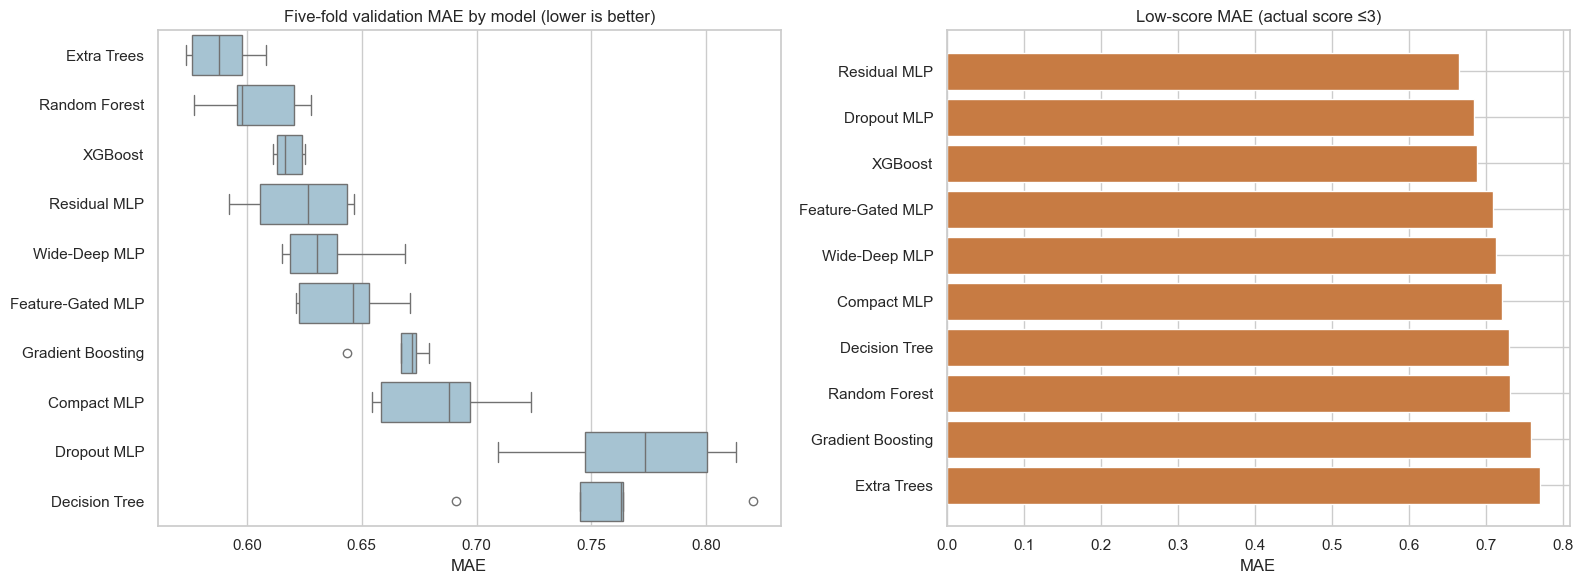

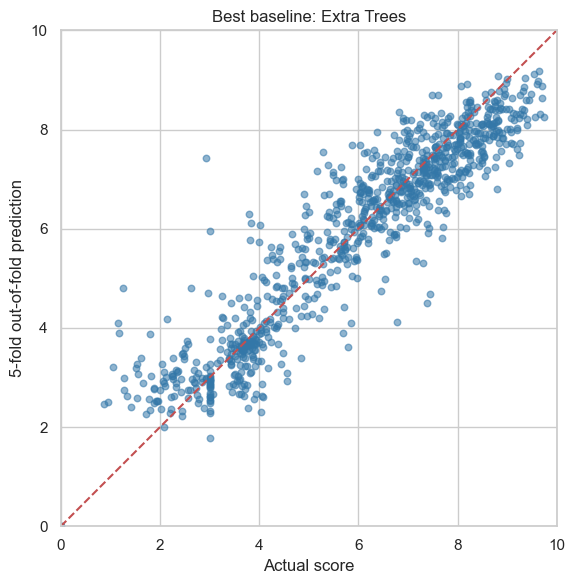

,Feature,Selected fold-model fits
0,pause_total_s,5
1,energy_peak_rate_proxy_min,5
2,pause_count_per_min,5
3,mfcc01_mean,5
4,speaking_time_ratio,5
5,vad_threshold_db,5
6,flatness_std,5
7,pause_mean_s,5
8,speech_rms_mean,5
9,pause_p90_s,5


Saved CV leaderboard: C:\Users\Admin\Music\rp\outputs\ten_model_five_fold_leaderboard.csv


In [5]:
all_oof = {**classic_oof, **dl_oof}
all_fold_results = pd.concat([classic_fold_results, dl_fold_results], ignore_index=True)
cv_rows = []
for model_name, pred in all_oof.items():
    cv_rows.append({"Model": model_name, **regression_metrics(y_dev, pred)})
cv_leaderboard = pd.DataFrame(cv_rows).sort_values(["MAE (weighted 0–3 priority)", "MAE", "RMSE"]).reset_index(drop=True)
cv_leaderboard.insert(0, "Rank", np.arange(1, len(cv_leaderboard)+1))
display(cv_leaderboard.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
order = cv_leaderboard.Model.tolist()
sns.boxplot(data=all_fold_results, x="MAE", y="Model", order=order, ax=axes[0], color="#9fc5d9")
axes[0].set(title="Five-fold validation MAE by model (lower is better)", xlabel="MAE", ylabel="")
low = cv_leaderboard.sort_values("MAE (score≤3)")
axes[1].barh(low.Model, low["MAE (score≤3)"], color="#c77b43")
axes[1].invert_yaxis(); axes[1].set(title="Low-score MAE (actual score ≤3)", xlabel="MAE", ylabel="")
fig.tight_layout(); display(fig); plt.close(fig)

best_name = cv_leaderboard.iloc[0].Model
best_pred = all_oof[best_name]
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_dev, best_pred, alpha=.55, s=22, color="#3377a8")
ax.plot([0, 10], [0, 10], ls="--", color="#c34f50")
ax.set(xlim=(0, 10), ylim=(0, 10), xlabel="Actual score", ylabel="5-fold out-of-fold prediction", title=f"Best baseline: {best_name}")
ax.set_aspect("equal", adjustable="box"); fig.tight_layout(); display(fig); plt.close(fig)

# Record the fold-wise selected feature frequencies (the same fold-local selector is shared by all models).
feature_array = np.asarray(FEATURE_COLUMNS)
selector_counts = pd.Series(np.concatenate([feature_array[indices] for indices in selected_features_by_fold])).value_counts()
feature_stability = selector_counts.rename_axis("Feature").reset_index(name="Selected fold-model fits")
display(feature_stability.head(25))
CV_FILE = OUTPUT_DIR / "ten_model_five_fold_leaderboard.csv"
FOLD_FILE = OUTPUT_DIR / "ten_model_fold_metrics.csv"
OOF_FILE = OUTPUT_DIR / "ten_model_oof_predictions.csv"
cv_leaderboard.to_csv(CV_FILE, index=False); all_fold_results.to_csv(FOLD_FILE, index=False)
pd.DataFrame({"actual": y_dev, **{k: v for k, v in all_oof.items()}}).to_csv(OOF_FILE, index=False)
print("Saved CV leaderboard:", CV_FILE)

## 5. Nested cross-validation for tuned models and the ensemble

The ten-model comparison above is a screening step. Each outer fold is now held aside for evaluation. Hyperparameters and blend weights are selected using only inner folds from that outer training partition. This gives a less biased development estimate for the shortlisted tuned candidates. Since the three classical families were shortlisted after the earlier ten-model screen, the estimate is conditional on that shortlist; a fully unbiased estimate of the entire ten-model selection process would also repeat that screening inside each outer fold. The final test set remains locked.


In [6]:
# Nested CV: all tuning and blend-weight choices stay inside each outer training fold.
classic_names = set(CLASSIC_BUILDERS)
search_grids = {
    "Extra Trees": [
        {"n_estimators": 500, "max_features": f, "min_samples_leaf": leaf, "max_depth": depth}
        for f, leaf, depth in [(0.45,1,None),(0.65,1,None),(0.85,1,None),(1.0,1,None),
                               (0.45,2,None),(0.65,2,None),(0.85,2,None),(0.65,4,18)]
    ],
    "Random Forest": [
        {"n_estimators": 500, "max_features": f, "min_samples_leaf": leaf, "max_depth": depth}
        for f, leaf, depth in [(0.45,1,None),(0.65,1,None),(0.85,2,None),
                               (1.0,2,None),(0.65,4,18),(0.45,3,24)]
    ],
    "XGBoost": [
        {"n_estimators": n, "learning_rate": lr, "max_depth": depth,
         "min_child_weight": child, "subsample": 0.85, "colsample_bytree": 0.8,
         "reg_lambda": reg}
        for n, lr, depth, child, reg in [(250,.025,2,2,3),(400,.025,2,4,5),
            (300,.04,3,2,3),(450,.03,3,5,5),(250,.05,2,5,8),(350,.04,4,4,8)]
    ],
}
def build_tuned_classic(name, params):
    model = CLASSIC_BUILDERS[name]()
    model.set_params(**params)
    return make_classic_pipeline(name, model=model)

from sklearn.model_selection import StratifiedKFold
def make_inner_folds(indices, n_splits=4):
    splitter = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED + int(indices[0]))
    return [(indices[tr], indices[va]) for tr, va in splitter.split(np.zeros(len(indices)), score_band(y_dev[indices]))]

weight_grid = [np.array([a, b, round(1-a-b, 10)])
               for a in np.arange(0, 1.001, .1)
               for b in np.arange(0, 1.001-a, .1) if 1-a-b >= -1e-9]
def choose_weights(actual, prediction_matrix):
    return min(weight_grid, key=lambda w: regression_metrics(actual, prediction_matrix @ w)["MAE (weighted 0–3 priority)"])

nested_oof = {name: np.full(len(y_dev), np.nan) for name in search_grids}
nested_ensemble_oof = np.full(len(y_dev), np.nan)
nested_rows, nested_weight_rows = [], []
for outer_no, (outer_train, outer_valid) in enumerate(FOLDS, 1):
    inner_folds = make_inner_folds(outer_train)
    outer_member_predictions = []
    for family, grid in search_grids.items():
        best = None
        position = {idx: pos for pos, idx in enumerate(outer_train)}
        for params in grid:
            inner_oof = np.full(len(outer_train), np.nan)
            for inner_train, inner_valid in inner_folds:
                model = build_tuned_classic(family, params)
                model.fit(X_dev.iloc[inner_train], y_dev[inner_train], model__sample_weight=low_score_weights(y_dev[inner_train]))
                pred = apply_silence_rule(model.predict(X_dev.iloc[inner_valid]), X_dev.iloc[inner_valid])
                inner_oof[[position[i] for i in inner_valid]] = pred
            score = regression_metrics(y_dev[outer_train], inner_oof)["MAE (weighted 0–3 priority)"]
            if best is None or score < best[0]: best = (score, params, inner_oof)
        _, params, inner_oof = best
        fitted = build_tuned_classic(family, params)
        fitted.fit(X_dev.iloc[outer_train], y_dev[outer_train], model__sample_weight=low_score_weights(y_dev[outer_train]))
        valid_pred = apply_silence_rule(fitted.predict(X_dev.iloc[outer_valid]), X_dev.iloc[outer_valid])
        nested_oof[family][outer_valid] = valid_pred
        outer_member_predictions.append((family, valid_pred, inner_oof))
        nested_rows.append({"Outer fold": outer_no, "Family": family, "Parameters": str(params), **regression_metrics(y_dev[outer_valid], valid_pred)})
    inner_matrix = np.column_stack([item[2] for item in outer_member_predictions])
    weights = choose_weights(y_dev[outer_train], inner_matrix)
    valid_matrix = np.column_stack([item[1] for item in outer_member_predictions])
    nested_ensemble_oof[outer_valid] = valid_matrix @ weights
    nested_weight_rows.append({"Outer fold": outer_no, **dict(zip(search_grids, weights))})
    print(f"Outer fold {outer_no}/5 complete; inner-selected blend weights: {dict(zip(search_grids, weights.round(2)))}")

nested_summary = pd.DataFrame(
    [{"Candidate": name, **regression_metrics(y_dev, pred)} for name, pred in nested_oof.items()] +
    [{"Candidate": "Nested weighted ensemble", **regression_metrics(y_dev, nested_ensemble_oof)}])
display(nested_summary.sort_values("MAE (weighted 0–3 priority)").round(3))
display(pd.DataFrame(nested_weight_rows).round(2))
nested_summary.to_csv(OUTPUT_DIR / "nested_cv_model_metrics.csv", index=False)
pd.DataFrame(nested_rows).to_csv(OUTPUT_DIR / "nested_cv_fold_metrics.csv", index=False)
pd.DataFrame({"actual": y_dev, **{f"nested_{k}": v for k, v in nested_oof.items()},
              "nested_ensemble": nested_ensemble_oof}).to_csv(OUTPUT_DIR / "nested_cv_oof_predictions.csv", index=False)


Outer fold 1/5 complete; inner-selected blend weights: {'Extra Trees': np.float64(0.0), 'Random Forest': np.float64(0.6), 'XGBoost': np.float64(0.4)}
Outer fold 2/5 complete; inner-selected blend weights: {'Extra Trees': np.float64(0.4), 'Random Forest': np.float64(0.3), 'XGBoost': np.float64(0.3)}
Outer fold 3/5 complete; inner-selected blend weights: {'Extra Trees': np.float64(0.4), 'Random Forest': np.float64(0.6), 'XGBoost': np.float64(-0.0)}
Outer fold 4/5 complete; inner-selected blend weights: {'Extra Trees': np.float64(0.5), 'Random Forest': np.float64(0.0), 'XGBoost': np.float64(0.5)}
Outer fold 5/5 complete; inner-selected blend weights: {'Extra Trees': np.float64(0.5), 'Random Forest': np.float64(0.2), 'XGBoost': np.float64(0.3)}


,Candidate,MAE (weighted 0–3 priority),MAE,RMSE,R²,Spearman,N (score=0),MAE (score=0),MAE (0<score≤3),N (score≤2),N (score≤3),N (score≤4),MAE (score≤2),MAE (score≤3),MAE (score≤4),Within ±1
3,Nested weighted ensemble,0.616,0.589,0.793,0.860,0.918,2,0.0,0.754,30,114,235,1.218,0.741,0.599,0.822
0,Extra Trees,0.620,0.586,0.786,0.863,0.921,2,0.0,0.782,30,114,235,1.301,0.768,0.605,0.818
1,Random Forest,0.621,0.601,0.817,0.852,0.913,2,0.0,0.743,30,114,235,1.192,0.730,0.584,0.806
2,XGBoost,0.632,0.614,0.816,0.852,0.912,2,0.0,0.728,30,114,235,1.122,0.715,0.611,0.821


,Outer fold,Extra Trees,Random Forest,XGBoost
0,1,0.0,0.6,0.4
1,2,0.4,0.3,0.3
2,3,0.4,0.6,-0.0
3,4,0.5,0.0,0.5
4,5,0.5,0.2,0.3


## 6. Choose the final candidate and refit using development data

Use nested out-of-fold results for the development selection decision. Then fit final hyperparameters and blend weights using development-only cross-validation. The final holdout is still untouched.


In [7]:
# Re-run each family's search across all development folds for final model fitting.
# These CV predictions fit final parameters/weights; nested CV above is the performance estimate.
ensemble_members = list(search_grids)
final_candidates = {}
for family, grid in search_grids.items():
    runs = []
    for params in grid:
        pred = np.full(len(y_dev), np.nan)
        for tr, va in FOLDS:
            model = build_tuned_classic(family, params)
            model.fit(X_dev.iloc[tr], y_dev[tr], model__sample_weight=low_score_weights(y_dev[tr]))
            pred[va] = apply_silence_rule(model.predict(X_dev.iloc[va]), X_dev.iloc[va])
        runs.append((regression_metrics(y_dev, pred)["MAE (weighted 0–3 priority)"], params, pred))
    _, params, pred = min(runs, key=lambda x: x[0])
    final_candidates[family] = {"params": params, "oof": pred}

member_oof = np.column_stack([final_candidates[name]["oof"] for name in ensemble_members])
ensemble_weights = choose_weights(y_dev, member_oof)
tuned_classic_params_by_name = {name: final_candidates[name]["params"] for name in ensemble_members}
best_single_name = min(ensemble_members, key=lambda name: nested_summary.loc[
    nested_summary["Candidate"] == name, "MAE (weighted 0–3 priority)"].iloc[0])
single_nested = regression_metrics(y_dev, nested_oof[best_single_name])
ensemble_nested = regression_metrics(y_dev, nested_ensemble_oof)
ensemble_used = (ensemble_nested["MAE (weighted 0–3 priority)"] <= single_nested["MAE (weighted 0–3 priority)"] * .995
                 and ensemble_nested["MAE (score≤3)"] <= single_nested["MAE (score≤3)"] + .05)
display(pd.DataFrame([
    {"Candidate": "Nested tuned " + best_single_name, **single_nested},
    {"Candidate": "Nested weighted ensemble", **ensemble_nested}]).round(3))
print("Final development-fit blend weights:", dict(zip(ensemble_members, ensemble_weights.round(3))))
print("Selected from nested development estimates:", "weighted ensemble" if ensemble_used else "tuned " + best_single_name)
chosen_name = best_single_name
chosen_params = final_candidates[chosen_name]["params"]
chosen_oof = nested_oof[best_single_name]
chosen_family = "Classical"
chosen_variant = "tuned"


,Candidate,MAE (weighted 0–3 priority),MAE,RMSE,R²,Spearman,N (score=0),MAE (score=0),MAE (0<score≤3),N (score≤2),N (score≤3),N (score≤4),MAE (score≤2),MAE (score≤3),MAE (score≤4),Within ±1
0,Nested tuned Extra Trees,0.620,0.586,0.786,0.863,0.921,2,0.0,0.782,30,114,235,1.301,0.768,0.605,0.818
1,Nested weighted ensemble,0.616,0.589,0.793,0.860,0.918,2,0.0,0.754,30,114,235,1.218,0.741,0.599,0.822


Final development-fit blend weights: {'Extra Trees': np.float64(0.4), 'Random Forest': np.float64(0.3), 'XGBoost': np.float64(0.3)}
Selected from nested development estimates: weighted ensemble


## 7. Refit and evaluate the selected model once on the final test set

This is the only cell that accesses the holdout. Run it only after the development workflow is frozen. Report this result as the final holdout estimate for the selected candidate; do not use it to revise model choices or claim a definitive ranking against candidates that were not evaluated on the holdout.


,Final model,MAE (weighted 0–3 priority),MAE,RMSE,R²,Spearman,N (score=0),MAE (score=0),MAE (0<score≤3),N (score≤2),N (score≤3),N (score≤4),MAE (score≤2),MAE (score≤3),MAE (score≤4),Within ±1
0,Weighted tuned ensemble: Extra Trees + Random ...,0.605,0.585,0.751,0.868,0.92,0,NaN,0.706,7,29,58,0.966,0.706,0.625,0.837


This is the only final-test evaluation. Do not tune further against these results.
Saved selected model: selected_fluency_ensemble.joblib


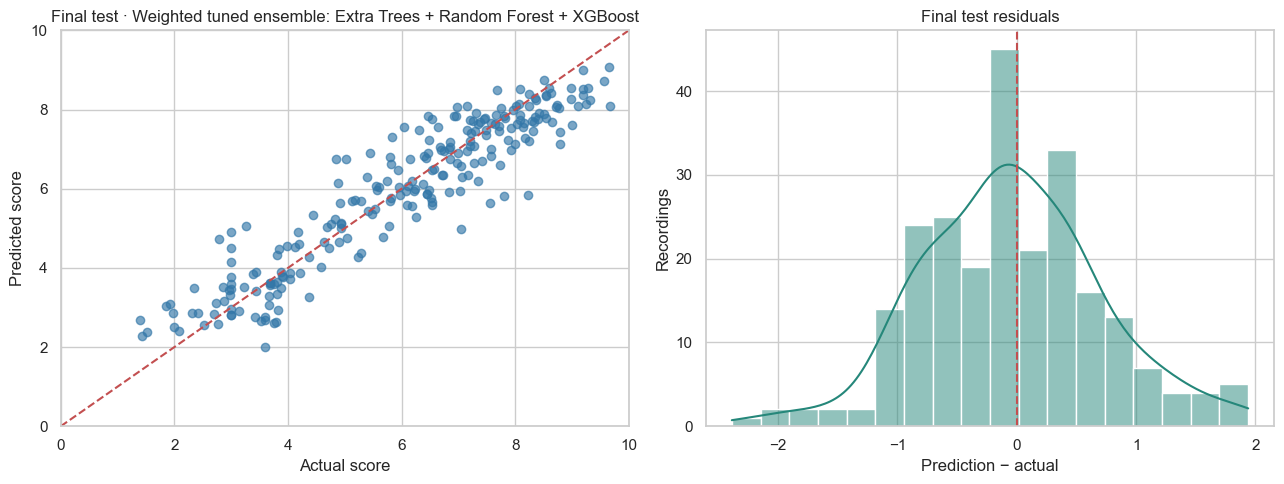

,file,actual,predicted,error,absolute_error
111,1107.wav,8.22,5.831766,-2.388234,2.388234
13,938.wav,7.05,4.981499,-2.068501,2.068501
231,1104.wav,7.80,5.822250,-1.977750,1.977750
214,727.wav,2.78,4.718948,1.938948,1.938948
44,620.wav,4.84,6.743471,1.903471,1.903471
193,941.wav,7.55,5.647442,-1.902558,1.902558
0,355.wav,3.00,4.898357,1.898357,1.898357
215,903.wav,3.26,5.051756,1.791756,1.791756
174,749.wav,5.02,6.757334,1.737334,1.737334
69,1248.wav,8.79,7.122946,-1.667054,1.667054


Final test rows with score ≤2:


,file,actual,predicted,error,absolute_error
21,220.wav,1.97,2.852537,0.882537,0.882537
22,170.wav,1.43,2.291480,0.861480,0.861480
66,196.wav,1.40,2.689657,1.289657,1.289657
134,206.wav,1.51,2.392934,0.882934,0.882934
142,147.wav,1.85,3.025858,1.175858,1.175858
172,240.wav,2.00,2.509628,0.509628,0.509628
234,443.wav,1.92,3.077284,1.157284,1.157284


In [8]:
# Refit the selected tuned model(s) on development rows. The final test is opened only here.
selected_test_prediction = None
fitted_final_models = {}
if ensemble_used:
    for name in ensemble_members:
        model=build_tuned_classic(name, tuned_classic_params_by_name[name])
        model.fit(X_dev, y_dev, model__sample_weight=low_score_weights(y_dev))
        fitted_final_models[name]=model
    raw_test=np.column_stack([fitted_final_models[name].predict(X_test) for name in ensemble_members]) @ ensemble_weights
    selected_test_prediction=apply_silence_rule(raw_test, X_test)
    final_name="Weighted tuned ensemble: "+" + ".join(ensemble_members)
else:
    final_model=build_tuned_classic(chosen_name, chosen_params)
    final_model.fit(X_dev, y_dev, model__sample_weight=low_score_weights(y_dev))
    fitted_final_models[chosen_name]=final_model
    selected_test_prediction=apply_silence_rule(final_model.predict(X_test), X_test)
    final_name=chosen_name+" (tuned)"

final_metrics = regression_metrics(y_test, selected_test_prediction)
final_table = pd.DataFrame([{"Final model": final_name, **final_metrics}])
display(final_table.round(3))
print("This is the only final-test evaluation. Do not tune further against these results.")

test_predictions = pd.DataFrame({"file": data.iloc[test_idx]["file"].to_numpy(), "actual": y_test,
                                 "predicted": selected_test_prediction, "error": selected_test_prediction-y_test,
                                 "absolute_error": np.abs(selected_test_prediction-y_test)})
test_predictions.to_csv(OUTPUT_DIR / "final_test_predictions.csv", index=False)
final_table.to_csv(OUTPUT_DIR / "final_test_metrics.csv", index=False)

# Save reusable model artifacts and the fold-local-selected input schema.
import joblib
model_metadata={"model":final_name, "feature_columns":FEATURE_COLUMNS,
    "score_min":0.0, "score_max":10.0,
    "low_score_weighting":"<=3:4x; >3 and <=5:2x; >5:1x, normalized per training fold",
    "feature_selection":"Top 25 absolute Spearman associations, fit on training data only",
    "cv_folds":5, "random_seed":SEED,
    "selection_variant":"weighted_ensemble" if ensemble_used else "tuned_single",
    "evaluation_unit":"recording-level; speaker IDs unavailable",
    "zero_score_rule":"silent_recording feature forces exact score 0; exact zeros separately reported"}
if ensemble_used:
    joblib.dump({"models":fitted_final_models, "members":ensemble_members,
                 "weights":ensemble_weights.tolist(), "feature_columns":FEATURE_COLUMNS},
                OUTPUT_DIR/"selected_fluency_ensemble.joblib")
    model_metadata["artifact"]="selected_fluency_ensemble.joblib"
    model_metadata["ensemble_weights"]=dict(zip(ensemble_members, ensemble_weights.tolist()))
    model_metadata["selected_parameters"]={name:tuned_classic_params_by_name[name] for name in ensemble_members}
else:
    joblib.dump(fitted_final_models[chosen_name], OUTPUT_DIR/"selected_fluency_model.joblib")
    model_metadata["artifact"]="selected_fluency_model.joblib"
    model_metadata["selected_parameters"]=chosen_params
    model_metadata["selected_parameters"]=chosen_params
(OUTPUT_DIR/"selected_fluency_model_metadata.json").write_text(json.dumps(model_metadata,indent=2),encoding="utf-8")
print("Saved selected model:", model_metadata["artifact"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, selected_test_prediction, alpha=.65, color="#3377a8")
axes[0].plot([0, 10], [0, 10], ls="--", color="#c34f50")
axes[0].set(xlim=(0,10), ylim=(0,10), xlabel="Actual score", ylabel="Predicted score", title=f"Final test · {final_name}")
residual = selected_test_prediction-y_test
sns.histplot(residual, bins=18, kde=True, ax=axes[1], color="#25877a")
axes[1].axvline(0, color="#c34f50", ls="--")
axes[1].set(title="Final test residuals", xlabel="Prediction − actual", ylabel="Recordings")
fig.tight_layout(); display(fig); plt.close(fig)
display(test_predictions.sort_values("absolute_error", ascending=False).head(15))
print("Final test rows with score ≤2:")
display(test_predictions.loc[test_predictions.actual <= 2])